In [2]:
%pip install yfinance pandas matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

print("Everything is working!")

Everything is working!


In [4]:
apple = yf.download(
    "AAPL",
    start="2015-01-01",
    end="2026-01-01",
    auto_adjust=True
)

print(apple.head())

[*********************100%***********************]  1 of 1 completed

Price           Close       High        Low       Open     Volume
Ticker           AAPL       AAPL       AAPL       AAPL       AAPL
Date                                                             
2015-01-02  24.153402  24.619548  23.715976  24.608501  212818400
2015-01-05  23.472969  24.003182  23.287395  23.923650  257142000
2015-01-06  23.475176  23.733654  23.115072  23.537034  263188400
2015-01-07  23.804348  23.903762  23.572379  23.682840  160423600
2015-01-08  24.718966  24.776406  24.014224  24.131314  237458000


In [5]:
print(apple.shape)

(2766, 5)


In [6]:
print(apple.isnull().sum())

Price   Ticker
Close   AAPL      0
High    AAPL      0
Low     AAPL      0
Open    AAPL      0
Volume  AAPL      0
dtype: int64


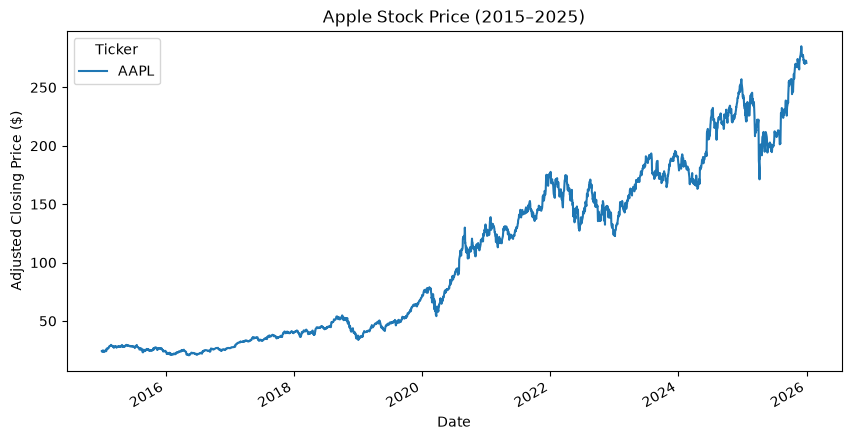

In [7]:
apple["Close"].plot(figsize=(10, 5))

plt.title("Apple Stock Price (2015–2025)")
plt.xlabel("Date")
plt.ylabel("Adjusted Closing Price ($)")
plt.show()


In [8]:

stocks = [
    "AAPL", "MSFT", "NVDA", "JPM", "GS",
    "AMZN", "WMT", "XOM", "KO", "JNJ"
]

stock_data = yf.download(
    stocks,
    start="2015-01-01",
    end="2026-01-01",
    auto_adjust=True,
    group_by="ticker"
)

print(stock_data.head())

[*********************100%***********************]  10 of 10 completed

Ticker              GS                                               \
Price             Open        High         Low       Close   Volume   
Date                                                                  
2015-01-02  154.823388  155.164263  152.762242  154.117844  1877700   
2015-01-05  153.047642  153.824530  148.624115  149.305878  3413200   
2015-01-06  149.274118  149.559507  145.809809  146.285461  3429200   
2015-01-07  148.124671  149.028401  147.268503  148.465546  1896800   
2015-01-08  150.106551  151.271889  150.027272  150.835876  1962500   

Ticker            JPM                                             ...  \
Price            Open       High        Low      Close    Volume  ...   
Date                                                              ...   
2015-01-02  45.610698  46.182849  45.530010  45.838093  12600000  ...   
2015-01-05  45.522682  45.684056  44.180326  44.415054  20100600  ...   
2015-01-06  44.481079  44.561767  42.801301  43.263424  29074100  

In [9]:
print(stock_data.shape)

(2766, 50)


In [10]:
stock_data.to_csv("stock_market_data.csv")

In [11]:
apple["Daily_Return"] = apple["Close"].pct_change()

print(apple[["Close", "Daily_Return"]].head(10))


Price           Close Daily_Return
Ticker           AAPL             
Date                              
2015-01-02  24.153402          NaN
2015-01-05  23.472969    -0.028171
2015-01-06  23.475176     0.000094
2015-01-07  23.804348     0.014022
2015-01-08  24.718966     0.038422
2015-01-09  24.745474     0.001072
2015-01-12  24.135731    -0.024641
2015-01-13  24.350023     0.008879
2015-01-14  24.257231    -0.003811
2015-01-15  23.598892    -0.027140


In [12]:
print(apple["Daily_Return"].mean())

0.0010394902206024893


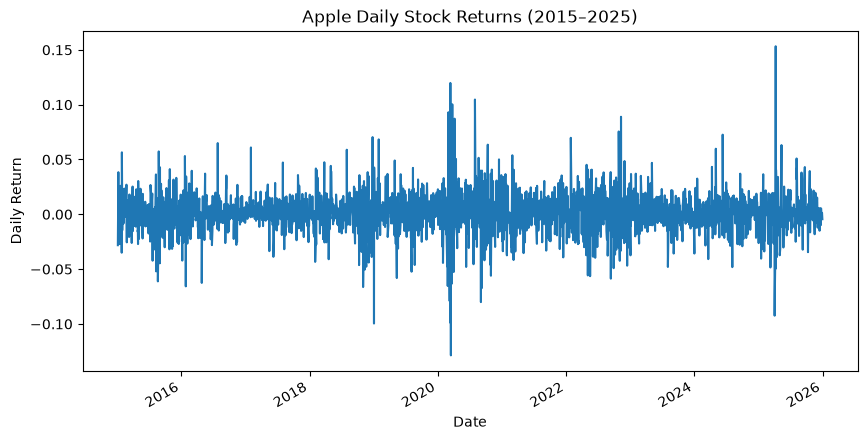

In [13]:
apple["Daily_Return"].plot(figsize=(10, 5))

plt.title("Apple Daily Stock Returns (2015–2025)")
plt.xlabel("Date")
plt.ylabel("Daily Return")
plt.show()

In [14]:
apple["Weekly_Return"] = apple["Close"].pct_change(5)

print(apple[["Close", "Daily_Return", "Weekly_Return"]].head(10))


Price           Close Daily_Return Weekly_Return
Ticker           AAPL                           
Date                                            
2015-01-02  24.153402          NaN           NaN
2015-01-05  23.472969    -0.028171           NaN
2015-01-06  23.475176     0.000094           NaN
2015-01-07  23.804348     0.014022           NaN
2015-01-08  24.718966     0.038422           NaN
2015-01-09  24.745474     0.001072      0.024513
2015-01-12  24.135731    -0.024641      0.028235
2015-01-13  24.350023     0.008879      0.037267
2015-01-14  24.257231    -0.003811      0.019025
2015-01-15  23.598892    -0.027140     -0.045312


In [15]:
apple["Volatility"] = apple["Daily_Return"].rolling(20).std()

print(apple[["Daily_Return", "Volatility"]].head(25))


Price      Daily_Return Volatility
Ticker                            
Date                              
2015-01-02          NaN        NaN
2015-01-05    -0.028171        NaN
2015-01-06     0.000094        NaN
2015-01-07     0.014022        NaN
2015-01-08     0.038422        NaN
2015-01-09     0.001072        NaN
2015-01-12    -0.024641        NaN
2015-01-13     0.008879        NaN
2015-01-14    -0.003811        NaN
2015-01-15    -0.027140        NaN
2015-01-16    -0.007770        NaN
2015-01-20     0.025757        NaN
2015-01-21     0.007634        NaN
2015-01-22     0.026016        NaN
2015-01-23     0.005160        NaN
2015-01-26     0.001062        NaN
2015-01-27    -0.035013        NaN
2015-01-28     0.056533        NaN
2015-01-29     0.031134        NaN
2015-01-30    -0.014634        NaN
2015-02-02     0.012547   0.023813
2015-02-03     0.000169   0.022587
2015-02-04     0.007670   0.022551
2015-02-05     0.007138   0.022477
2015-02-06    -0.008421   0.021310


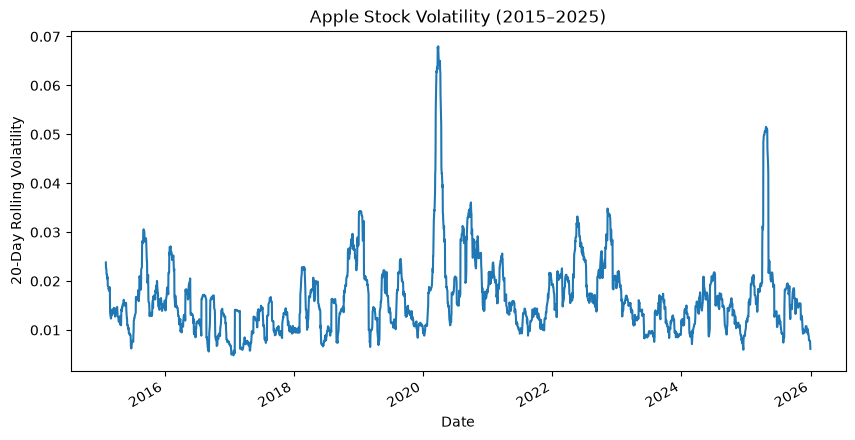

In [16]:
apple["Volatility"].plot(figsize=(10, 5))

plt.title("Apple Stock Volatility (2015–2025)")
plt.xlabel("Date")
plt.ylabel("20-Day Rolling Volatility")
plt.show()

In [17]:
all_stocks = stock_data.stack(level=0, future_stack=True).reset_index()

print(all_stocks.head())

Price       Date Ticker        Open        High         Low       Close  \
0     2015-01-02     GS  154.823388  155.164263  152.762242  154.117844   
1     2015-01-02    JPM   45.610698   46.182849   45.530010   45.838093   
2     2015-01-02    XOM   56.423164   56.912472   56.154044   56.777912   
3     2015-01-02   MSFT   39.522487   40.166230   39.420844   39.607189   
4     2015-01-02   NVDA    0.481884    0.485475    0.474223    0.481884   

Price     Volume  
0        1877700  
1       12600000  
2       10220400  
3       27913900  
4      113680000  


In [18]:
print(all_stocks.shape)
print(all_stocks.columns)


(27660, 7)
Index(['Date', 'Ticker', 'Open', 'High', 'Low', 'Close', 'Volume'], dtype='str', name='Price')


In [19]:
all_stocks = all_stocks.sort_values(
    ["Ticker", "Date"]
).reset_index(drop=True)

print(all_stocks.head())


Price       Date Ticker       Open       High        Low      Close     Volume
0     2015-01-02   AAPL  24.608501  24.619548  23.715976  24.153402  212818400
1     2015-01-05   AAPL  23.923650  24.003182  23.287395  23.472969  257142000
2     2015-01-06   AAPL  23.537034  23.733654  23.115072  23.475176  263188400
3     2015-01-07   AAPL  23.682840  23.903762  23.572379  23.804348  160423600
4     2015-01-08   AAPL  24.131314  24.776406  24.014224  24.718966  237458000


In [20]:
all_stocks["Daily_Return"] = (
    all_stocks.groupby("Ticker")["Close"].pct_change()
)

print(all_stocks[["Ticker", "Date", "Close", "Daily_Return"]].head(10))


Price Ticker       Date      Close  Daily_Return
0       AAPL 2015-01-02  24.153402           NaN
1       AAPL 2015-01-05  23.472969     -0.028171
2       AAPL 2015-01-06  23.475176      0.000094
3       AAPL 2015-01-07  23.804348      0.014022
4       AAPL 2015-01-08  24.718966      0.038422
5       AAPL 2015-01-09  24.745474      0.001072
6       AAPL 2015-01-12  24.135731     -0.024641
7       AAPL 2015-01-13  24.350023      0.008879
8       AAPL 2015-01-14  24.257231     -0.003811
9       AAPL 2015-01-15  23.598892     -0.027140


In [21]:
all_stocks["Weekly_Return"] = (
    all_stocks.groupby("Ticker")["Close"].pct_change(5)
)

print(all_stocks[["Ticker", "Date", "Weekly_Return"]].head(10))

Price Ticker       Date  Weekly_Return
0       AAPL 2015-01-02            NaN
1       AAPL 2015-01-05            NaN
2       AAPL 2015-01-06            NaN
3       AAPL 2015-01-07            NaN
4       AAPL 2015-01-08            NaN
5       AAPL 2015-01-09       0.024513
6       AAPL 2015-01-12       0.028235
7       AAPL 2015-01-13       0.037267
8       AAPL 2015-01-14       0.019025
9       AAPL 2015-01-15      -0.045312


In [22]:
all_stocks["Volatility"] = (
    all_stocks.groupby("Ticker")["Daily_Return"]
    .transform(lambda x: x.rolling(20).std())
)

print(all_stocks[["Ticker", "Date", "Volatility"]].head(25))


Price Ticker       Date  Volatility
0       AAPL 2015-01-02         NaN
1       AAPL 2015-01-05         NaN
2       AAPL 2015-01-06         NaN
3       AAPL 2015-01-07         NaN
4       AAPL 2015-01-08         NaN
5       AAPL 2015-01-09         NaN
6       AAPL 2015-01-12         NaN
7       AAPL 2015-01-13         NaN
8       AAPL 2015-01-14         NaN
9       AAPL 2015-01-15         NaN
10      AAPL 2015-01-16         NaN
11      AAPL 2015-01-20         NaN
12      AAPL 2015-01-21         NaN
13      AAPL 2015-01-22         NaN
14      AAPL 2015-01-23         NaN
15      AAPL 2015-01-26         NaN
16      AAPL 2015-01-27         NaN
17      AAPL 2015-01-28         NaN
18      AAPL 2015-01-29         NaN
19      AAPL 2015-01-30         NaN
20      AAPL 2015-02-02    0.023813
21      AAPL 2015-02-03    0.022587
22      AAPL 2015-02-04    0.022551
23      AAPL 2015-02-05    0.022477
24      AAPL 2015-02-06    0.021310


In [23]:
all_stocks["MA_20"] = (
    all_stocks.groupby("Ticker")["Close"]
    .transform(lambda x: x.rolling(20).mean())
)

all_stocks["MA_50"] = (
    all_stocks.groupby("Ticker")["Close"]
    .transform(lambda x: x.rolling(50).mean())
)

print(all_stocks[["Ticker", "Date", "Close", "MA_20", "MA_50"]].tail(10))

Price Ticker       Date       Close       MA_20       MA_50
27650    XOM 2025-12-17  115.101013  114.605442  112.936868
27651    XOM 2025-12-18  114.248116  114.565738  113.005661
27652    XOM 2025-12-19  114.395164  114.549563  113.098970
27653    XOM 2025-12-22  115.826454  114.602011  113.263276
27654    XOM 2025-12-23  117.071472  114.771119  113.423133
27655    XOM 2025-12-24  116.875404  115.001988  113.578097
27656    XOM 2025-12-26  116.767570  115.214721  113.744121
27657    XOM 2025-12-29  118.159645  115.440688  113.956841
27658    XOM 2025-12-30  118.610596  115.654401  114.147481
27659    XOM 2025-12-31  117.973381  115.897523  114.316435


In [24]:
print("Dataset shape:", all_stocks.shape)

print("\nColumn names:")
print(all_stocks.columns)

print("\nMissing values:")
print(all_stocks.isnull().sum())

all_stocks.to_csv(
    "stock_market_processed.csv",
    index=False
)

print("\nDataset saved successfully!")

Dataset shape: (27660, 12)

Column names:
Index(['Date', 'Ticker', 'Open', 'High', 'Low', 'Close', 'Volume',
       'Daily_Return', 'Weekly_Return', 'Volatility', 'MA_20', 'MA_50'],
      dtype='str', name='Price')

Missing values:
Price
Date               0
Ticker             0
Open               0
High               0
Low                0
Close              0
Volume             0
Daily_Return      10
Weekly_Return     50
Volatility       200
MA_20            190
MA_50            490
dtype: int64

Dataset saved successfully!


In [25]:
# Step 21: Create our prediction target

all_stocks = all_stocks.sort_values(
    by=["Ticker", "Date"]
).copy()

# Calculate the return over the next 5 trading days
all_stocks["Future_5D_Return"] = (
    all_stocks.groupby("Ticker")["Close"].shift(-5)
    / all_stocks["Close"] - 1
)

# Create a binary prediction target
all_stocks["Target"] = (
    all_stocks["Future_5D_Return"] > 0
).astype(int)

# Remove rows without a future 5-day return
all_stocks = all_stocks.dropna(
    subset=["Future_5D_Return"]
)

# Check our results
print(all_stocks[
    ["Date", "Ticker", "Close", "Future_5D_Return", "Target"]
].head(10))

Price       Date Ticker      Close  Future_5D_Return  Target
0     2015-01-02   AAPL  24.153402          0.024513       1
1     2015-01-05   AAPL  23.472969          0.028235       1
2     2015-01-06   AAPL  23.475176          0.037267       1
3     2015-01-07   AAPL  23.804348          0.019025       1
4     2015-01-08   AAPL  24.718966         -0.045312       0
5     2015-01-09   AAPL  24.745474         -0.053745       0
6     2015-01-12   AAPL  24.135731         -0.004851       0
7     2015-01-13   AAPL  24.350023         -0.006079       0
8     2015-01-14   AAPL  24.257231          0.023680       1
9     2015-01-15   AAPL  23.598892          0.057667       1


Target Distribution:
Target
1    15567
0    12043
Name: count, dtype: int64

Target Percentages:
Target
1    56.381746
0    43.618254
Name: proportion, dtype: float64


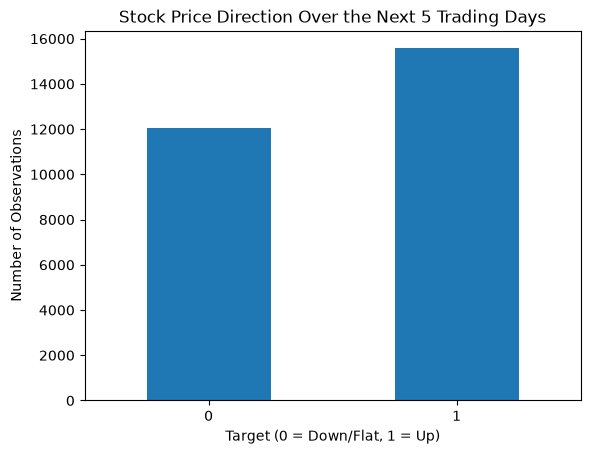

In [26]:
# Step 22: Analyze our prediction target

print("Target Distribution:")
print(all_stocks["Target"].value_counts())

print("\nTarget Percentages:")
print(all_stocks["Target"].value_counts(normalize=True) * 100)

# Visualize the distribution
import matplotlib.pyplot as plt

all_stocks["Target"].value_counts().sort_index().plot(
    kind="bar",
    title="Stock Price Direction Over the Next 5 Trading Days"
)

plt.xlabel("Target (0 = Down/Flat, 1 = Up)")
plt.ylabel("Number of Observations")
plt.xticks(rotation=0)
plt.show()

In [27]:
# Step 23: Prepare features and target

# Select the features for our machine learning model
features = [
    "Daily_Return",
    "Weekly_Return",
    "Volatility",
    "MA_20",
    "MA_50",
    "Volume"
]

# Remove rows with missing feature values
model_data = all_stocks.dropna(subset=features).copy()

# Define our features (X) and target (y)
X = model_data[features]
y = model_data["Target"]

# Check our data
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.head())

print("\nTarget:")
print(y.head())

Features shape: (27120, 6)
Target shape: (27120,)

Features:
Price  Daily_Return  Weekly_Return  Volatility      MA_20      MA_50  \
49         0.011004      -0.017225    0.013712  28.325523  26.494695   
50         0.016727       0.020320    0.014193  28.316762  26.575161   
51         0.011256       0.050965    0.014339  28.313989  26.675579   
52        -0.007550       0.024508    0.014433  28.303454  26.771650   
53        -0.012549       0.018691    0.014538  28.263532  26.854040   

Price     Volume  
49     143497200  
50     204092400  
51     261083600  
52     183238000  
53     274780400  

Target:
49    1
50    0
51    0
52    0
53    0
Name: Target, dtype: int64


In [28]:
# Step 24: Split data into training and testing sets

# Sort observations chronologically
model_data = model_data.sort_values("Date").copy()

# Find the 80% cutoff date
dates = sorted(model_data["Date"].unique())
split_index = int(len(dates) * 0.80)
split_date = dates[split_index]

# Split data based on date
train_data = model_data[model_data["Date"] < split_date].copy()
test_data = model_data[model_data["Date"] >= split_date].copy()

# Remove training observations whose 5-day target
# could extend into the testing period
train_data = train_data.sort_values(["Ticker", "Date"])

train_data = train_data.groupby("Ticker", group_keys=False).apply(
    lambda group: group.iloc[:-5]
).reset_index(drop=True)

# Separate features and target
X_train = train_data[features]
X_test = test_data[features]

y_train = train_data["Target"]
y_test = test_data["Target"]

# Display results
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining date range:")
print(train_data["Date"].min(), "to", train_data["Date"].max())

print("\nTesting date range:")
print(test_data["Date"].min(), "to", test_data["Date"].max())

Training observations: 21640
Testing observations: 5430

Training date range:
2015-03-16 00:00:00 to 2023-10-17 00:00:00

Testing date range:
2023-10-25 00:00:00 to 2025-12-23 00:00:00


In [29]:
# Step 25: Train a Logistic Regression model

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# Standardize our financial features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create our Logistic Regression model
log_model = LogisticRegression(max_iter=1000)

# Train the model using historical stock data
log_model.fit(X_train_scaled, y_train)

# Make predictions on the testing data
log_predictions = log_model.predict(X_test_scaled)

# Evaluate model accuracy
log_accuracy = accuracy_score(y_test, log_predictions)

print("Logistic Regression Accuracy:", round(log_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, log_predictions))

Logistic Regression Accuracy: 54.92 %

Classification Report:
              precision    recall  f1-score   support

           0       0.39      0.20      0.26      2211
           1       0.59      0.79      0.67      3219

    accuracy                           0.55      5430
   macro avg       0.49      0.49      0.47      5430
weighted avg       0.51      0.55      0.51      5430



In [30]:
# Step 26: Train a Random Forest model

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create our Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=-1
)

# Train the model using historical stock data
rf_model.fit(X_train, y_train)

# Make predictions on the testing data
rf_predictions = rf_model.predict(X_test)

# Evaluate model accuracy
rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, rf_predictions))

Random Forest Accuracy: 54.71 %

Classification Report:
              precision    recall  f1-score   support

           0       0.42      0.28      0.34      2211
           1       0.60      0.73      0.66      3219

    accuracy                           0.55      5430
   macro avg       0.51      0.51      0.50      5430
weighted avg       0.52      0.55      0.53      5430



                 Model  Accuracy (%)
0             Baseline         59.28
1  Logistic Regression         54.92
2        Random Forest         54.71


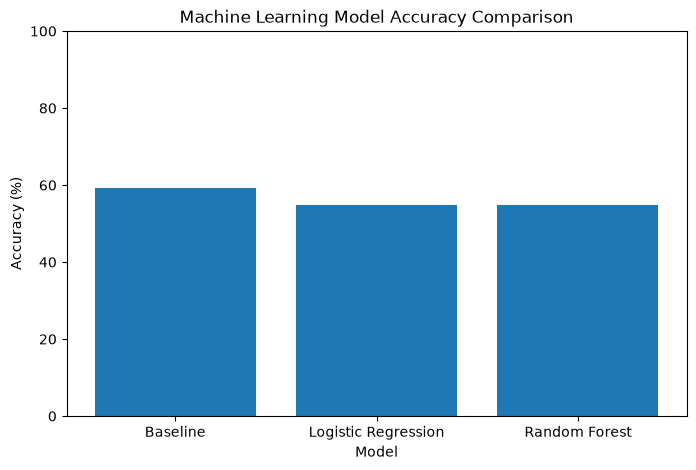

In [31]:
# Step 27: Compare Machine Learning Models

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# Calculate baseline accuracy
majority_class = y_train.mode()[0]
baseline_predictions = [majority_class] * len(y_test)

baseline_accuracy = accuracy_score(
    y_test, baseline_predictions
)

# Create comparison table
model_comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        baseline_accuracy,
        log_accuracy,
        rf_accuracy
    ]
})

# Convert accuracy to percentages
model_comparison["Accuracy (%)"] = (
    model_comparison["Accuracy"] * 100
).round(2)

print(model_comparison[["Model", "Accuracy (%)"]])

# Visualize model performance
plt.figure(figsize=(8, 5))

plt.bar(
    model_comparison["Model"],
    model_comparison["Accuracy (%)"]
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.show()

Random Forest Feature Importance:
         Feature  Importance
3          MA_20    0.263176
4          MA_50    0.241781
5         Volume    0.154740
2     Volatility    0.148376
1  Weekly_Return    0.104100
0   Daily_Return    0.087827


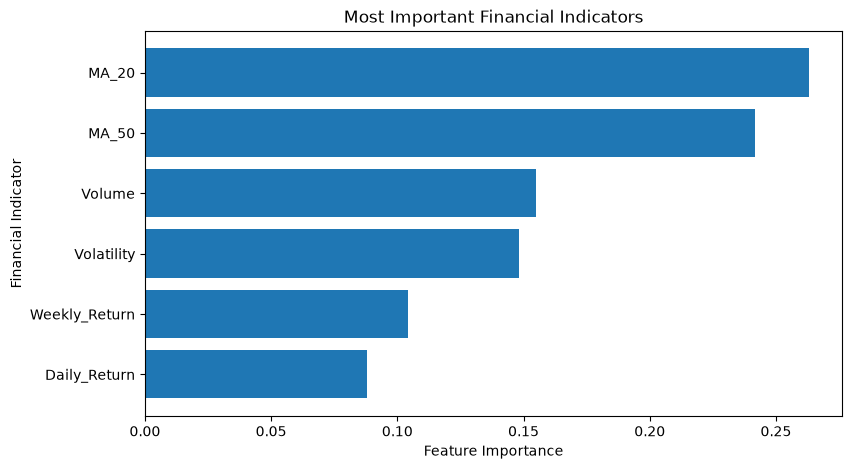

In [32]:
# Step 28: Analyze feature importance

import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance from Random Forest
importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

# Sort from most important to least important
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("Random Forest Feature Importance:")
print(importance)

# Visualize feature importance
plt.figure(figsize=(9, 5))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.title("Most Important Financial Indicators")
plt.xlabel("Feature Importance")
plt.ylabel("Financial Indicator")
plt.gca().invert_yaxis()

plt.show()

In [33]:
# Step 29: Create improved financial indicators

# Price relative to 20-day moving average
all_stocks["MA20_Ratio"] = (
    all_stocks["Close"] / all_stocks["MA_20"] - 1
)

# Price relative to 50-day moving average
all_stocks["MA50_Ratio"] = (
    all_stocks["Close"] / all_stocks["MA_50"] - 1
)

# Difference between moving averages
all_stocks["MA_Crossover"] = (
    all_stocks["MA_20"] / all_stocks["MA_50"] - 1
)

# Update our feature list
features = [
    "Daily_Return",
    "Weekly_Return",
    "Volatility",
    "MA20_Ratio",
    "MA50_Ratio",
    "MA_Crossover",
    "Volume"
]

print("Updated Financial Features:")
print(all_stocks[features].head(10))

Updated Financial Features:
Price  Daily_Return  Weekly_Return  Volatility  MA20_Ratio  MA50_Ratio  \
0               NaN            NaN         NaN         NaN         NaN   
1         -0.028171            NaN         NaN         NaN         NaN   
2          0.000094            NaN         NaN         NaN         NaN   
3          0.014022            NaN         NaN         NaN         NaN   
4          0.038422            NaN         NaN         NaN         NaN   
5          0.001072       0.024513         NaN         NaN         NaN   
6         -0.024641       0.028235         NaN         NaN         NaN   
7          0.008879       0.037267         NaN         NaN         NaN   
8         -0.003811       0.019025         NaN         NaN         NaN   
9         -0.027140      -0.045312         NaN         NaN         NaN   

Price  MA_Crossover     Volume  
0               NaN  212818400  
1               NaN  257142000  
2               NaN  263188400  
3               NaN  1604

In [34]:
# Step 30: Retrain models with improved features

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Prepare updated dataset
updated_data = all_stocks.dropna(subset=features).copy()

# Use the same training/testing cutoff as before
updated_train = updated_data[
    updated_data["Date"] < split_date
].copy()

updated_test = updated_data[
    updated_data["Date"] >= split_date
].copy()

# Remove last 5 training observations per stock
# to prevent future target leakage
updated_train = updated_train.sort_values(
    ["Ticker", "Date"]
)

updated_train = (
    updated_train.groupby("Ticker", group_keys=False)
    .apply(lambda group: group.iloc[:-5])
    .reset_index(drop=True)
)

# Separate features and target
X_train_new = updated_train[features]
X_test_new = updated_test[features]

y_train_new = updated_train["Target"]
y_test_new = updated_test["Target"]

# Scale features for Logistic Regression
scaler_new = StandardScaler()

X_train_scaled_new = scaler_new.fit_transform(X_train_new)
X_test_scaled_new = scaler_new.transform(X_test_new)

# Train Logistic Regression
log_model_new = LogisticRegression(max_iter=1000)
log_model_new.fit(X_train_scaled_new, y_train_new)

log_predictions_new = log_model_new.predict(
    X_test_scaled_new
)

log_accuracy_new = accuracy_score(
    y_test_new, log_predictions_new
)

# Train Random Forest
rf_model_new = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=-1
)

rf_model_new.fit(X_train_new, y_train_new)

rf_predictions_new = rf_model_new.predict(X_test_new)

rf_accuracy_new = accuracy_score(
    y_test_new, rf_predictions_new
)

# Display updated results
print("Updated Model Accuracy Results")
print("--------------------------------")

print(
    "Logistic Regression:",
    round(log_accuracy_new * 100, 2), "%"
)

print(
    "Random Forest:",
    round(rf_accuracy_new * 100, 2), "%"
)

Updated Model Accuracy Results
--------------------------------
Logistic Regression: 59.28 %
Random Forest: 58.95 %


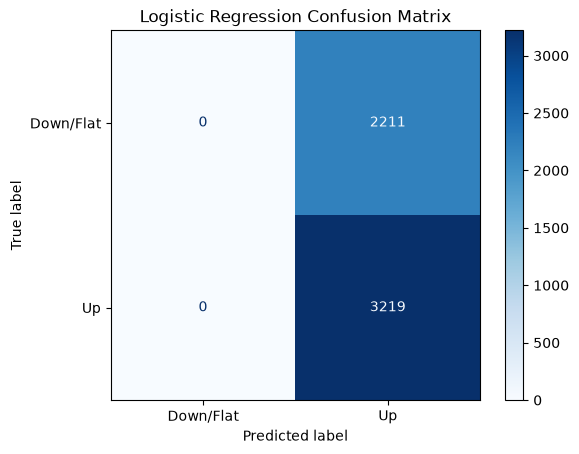

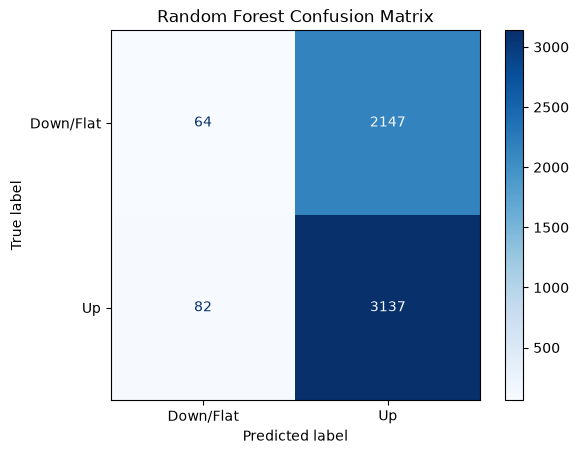

In [35]:
# Step 32: Evaluate models using confusion matrices

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create confusion matrices
log_cm = confusion_matrix(y_test_new, log_predictions_new)
rf_cm = confusion_matrix(y_test_new, rf_predictions_new)

# Display Logistic Regression confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=log_cm,
    display_labels=["Down/Flat", "Up"]
).plot(cmap="Blues")

plt.title("Logistic Regression Confusion Matrix")
plt.show()

# Display Random Forest confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=["Down/Flat", "Up"]
).plot(cmap="Blues")

plt.title("Random Forest Confusion Matrix")
plt.show()

In [36]:
# Step 33: Evaluate precision, recall, and F1 scores

from sklearn.metrics import classification_report, balanced_accuracy_score

print("LOGISTIC REGRESSION")
print(classification_report(
    y_test_new,
    log_predictions_new,
    target_names=["Down/Flat", "Up"],
    zero_division=0
))

print("Balanced Accuracy:",
      round(balanced_accuracy_score(
          y_test_new, log_predictions_new
      ) * 100, 2), "%")

print("\nRANDOM FOREST")
print(classification_report(
    y_test_new,
    rf_predictions_new,
    target_names=["Down/Flat", "Up"],
    zero_division=0
))

print("Balanced Accuracy:",
      round(balanced_accuracy_score(
          y_test_new, rf_predictions_new
      ) * 100, 2), "%")

LOGISTIC REGRESSION
              precision    recall  f1-score   support

   Down/Flat       0.00      0.00      0.00      2211
          Up       0.59      1.00      0.74      3219

    accuracy                           0.59      5430
   macro avg       0.30      0.50      0.37      5430
weighted avg       0.35      0.59      0.44      5430

Balanced Accuracy: 50.0 %

RANDOM FOREST
              precision    recall  f1-score   support

   Down/Flat       0.44      0.03      0.05      2211
          Up       0.59      0.97      0.74      3219

    accuracy                           0.59      5430
   macro avg       0.52      0.50      0.40      5430
weighted avg       0.53      0.59      0.46      5430

Balanced Accuracy: 50.17 %


In [37]:
# Step 34: Generate stock prediction probabilities

import pandas as pd

# Get probability of stock increasing
log_probabilities = log_model_new.predict_proba(
    X_test_scaled_new
)[:, 1]

rf_probabilities = rf_model_new.predict_proba(
    X_test_new
)[:, 1]

# Create a results dataframe
prediction_results = updated_test[
    ["Date", "Ticker", "Close"]
].copy()

# Add actual stock movement
prediction_results["Actual"] = y_test_new.values

# Add predicted probabilities
prediction_results["Logistic_Probability"] = log_probabilities
prediction_results["RF_Probability"] = rf_probabilities

# Display results
print("Stock Prediction Probabilities:")
print(prediction_results.head(10))

Stock Prediction Probabilities:
Price       Date Ticker       Close  Actual  Logistic_Probability  \
2218  2023-10-25   AAPL  168.688599       1              0.558398   
2219  2023-10-26   AAPL  164.537918       1              0.561848   
2220  2023-10-27   AAPL  165.849136       1              0.549854   
2221  2023-10-30   AAPL  167.889954       1              0.548608   
2222  2023-10-31   AAPL  168.363235       1              0.551496   
2223  2023-11-01   AAPL  171.518112       1              0.547461   
2224  2023-11-02   AAPL  175.067383       1              0.548110   
2225  2023-11-03   AAPL  174.160339       1              0.557046   
2226  2023-11-06   AAPL  176.703995       1              0.550626   
2227  2023-11-07   AAPL  179.257507       1              0.552113   

Price  RF_Probability  
2218         0.571493  
2219         0.587469  
2220         0.577656  
2221         0.560126  
2222         0.566710  
2223         0.554065  
2224         0.549908  
2225         0.5

In [38]:
# Step 35: Rank stocks by predicted probability

# Find the most recent date in our predictions
latest_date = prediction_results["Date"].max()

# Select predictions from that date
latest_predictions = prediction_results[
    prediction_results["Date"] == latest_date
].copy()

# Rank stocks using Random Forest probabilities
stock_rankings = latest_predictions.sort_values(
    by="RF_Probability",
    ascending=False
).copy()

# Convert probabilities to percentages
stock_rankings["RF_Probability"] = (
    stock_rankings["RF_Probability"] * 100
).round(2)

stock_rankings["Logistic_Probability"] = (
    stock_rankings["Logistic_Probability"] * 100
).round(2)

# Display rankings
print("Stock Rankings for:", latest_date)

print(stock_rankings[
    [
        "Ticker",
        "Close",
        "Logistic_Probability",
        "RF_Probability"
    ]
].to_string(index=False))

Stock Rankings for: 2025-12-23 00:00:00
Ticker      Close  Logistic_Probability  RF_Probability
   XOM 117.071472                 54.73           56.08
  AAPL 271.414398                 54.66           56.00
   WMT 110.198242                 55.07           55.97
  MSFT 483.780792                 55.03           55.87
  NVDA 188.768280                 55.60           55.18
  AMZN 232.139999                 54.64           55.17
   JPM 319.771271                 55.07           53.56
    GS 888.700989                 55.60           51.92
   JNJ 202.522552                 55.03           51.10
    KO  68.538734                 55.03           50.68


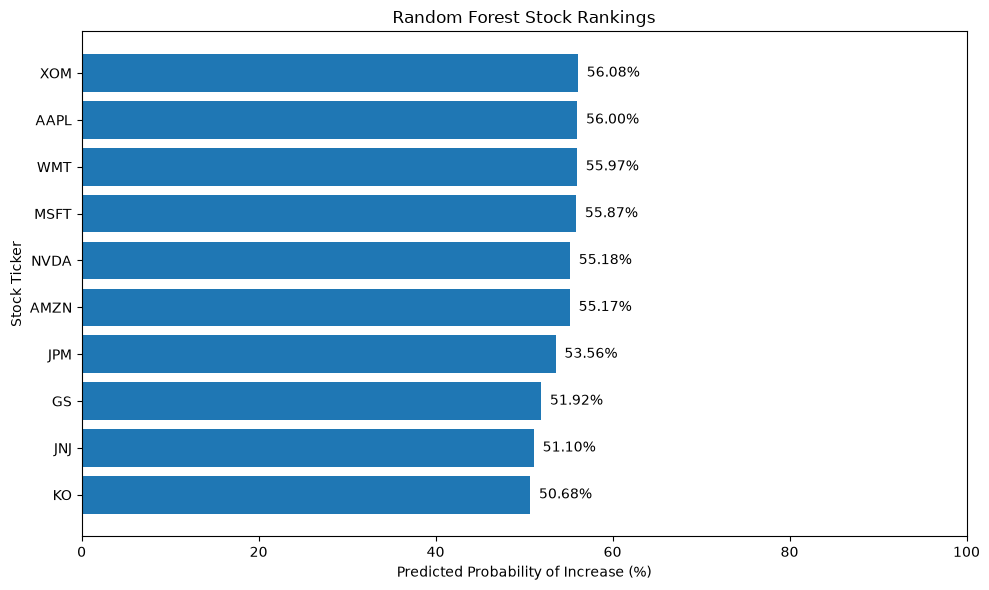

In [39]:
# Step 36: Visualize stock rankings

import matplotlib.pyplot as plt

# Sort stocks from lowest to highest for plotting
plot_data = stock_rankings.sort_values(
    by="RF_Probability",
    ascending=True
)

# Create horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["Ticker"],
    plot_data["RF_Probability"]
)

plt.title("Random Forest Stock Rankings")
plt.xlabel("Predicted Probability of Increase (%)")
plt.ylabel("Stock Ticker")
plt.xlim(0, 100)

# Add probability labels
for i, value in enumerate(plot_data["RF_Probability"]):
    plt.text(value + 1, i, f"{value:.2f}%", va="center")

plt.tight_layout()
plt.show()

Average 5-Day Returns
---------------------
Machine Learning Strategy: 0.79 %
Equal-Weight Benchmark: 0.69 %


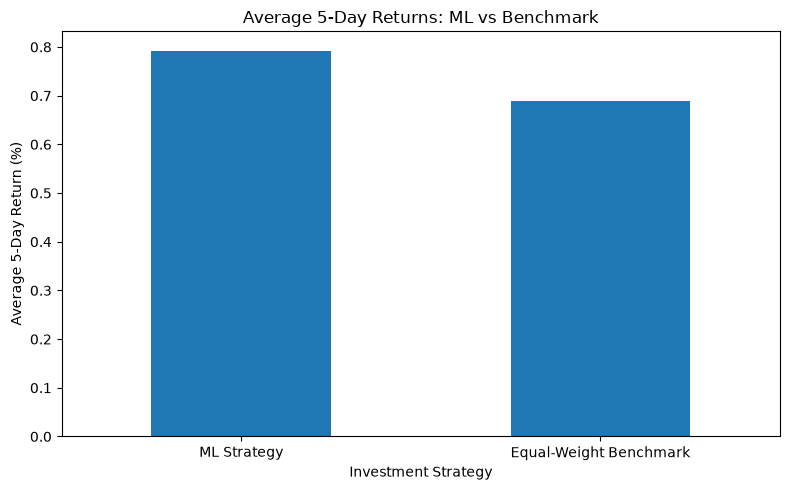

In [40]:
# Step 37: Backtest our stock selection strategy

import pandas as pd
import matplotlib.pyplot as plt

# Add actual future returns to our prediction results
backtest_data = prediction_results.copy()

backtest_data["Future_5D_Return"] = updated_test[
    "Future_5D_Return"
].to_numpy()

# Sort by date and predicted probability
backtest_data = backtest_data.sort_values(
    ["Date", "RF_Probability"],
    ascending=[True, False]
)

# Select top 3 stocks for each date
top_3 = backtest_data.groupby("Date").head(3)

# Calculate average 5-day return of top 3 stocks
ml_returns = top_3.groupby("Date")[
    "Future_5D_Return"
].mean()

# Calculate average 5-day return of all 10 stocks
benchmark_returns = backtest_data.groupby("Date")[
    "Future_5D_Return"
].mean()

# Compare average returns
print("Average 5-Day Returns")
print("---------------------")

print(
    "Machine Learning Strategy:",
    round(ml_returns.mean() * 100, 2), "%"
)

print(
    "Equal-Weight Benchmark:",
    round(benchmark_returns.mean() * 100, 2), "%"
)

# Create comparison chart
comparison = pd.DataFrame({
    "ML Strategy": ml_returns,
    "Equal-Weight Benchmark": benchmark_returns
}).dropna()

comparison.mean().mul(100).plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average 5-Day Returns: ML vs Benchmark")
plt.ylabel("Average 5-Day Return (%)")
plt.xlabel("Investment Strategy")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [41]:
# Step 38: Evaluate investment strategy performance

import pandas as pd

# Compare the two strategies
strategy_results = pd.DataFrame({
    "ML_Strategy": ml_returns,
    "Benchmark": benchmark_returns
}).dropna()

# Calculate difference in returns
strategy_results["Difference"] = (
    strategy_results["ML_Strategy"]
    - strategy_results["Benchmark"]
)

# Calculate performance metrics
print("Investment Strategy Evaluation")
print("--------------------------------")

print("Average ML Return:",
      round(strategy_results["ML_Strategy"].mean() * 100, 2), "%")

print("Average Benchmark Return:",
      round(strategy_results["Benchmark"].mean() * 100, 2), "%")

print("Average Outperformance:",
      round(strategy_results["Difference"].mean() * 100, 2),
      "percentage points")

print("ML Strategy Win Rate:",
      round((strategy_results["Difference"] > 0).mean() * 100, 2), "%")

print("ML Strategy Return Volatility:",
      round(strategy_results["ML_Strategy"].std() * 100, 2), "%")

print("Benchmark Return Volatility:",
      round(strategy_results["Benchmark"].std() * 100, 2), "%")

Investment Strategy Evaluation
--------------------------------
Average ML Return: 0.79 %
Average Benchmark Return: 0.69 %
Average Outperformance: 0.1 percentage points
ML Strategy Win Rate: 49.91 %
ML Strategy Return Volatility: 2.96 %
Benchmark Return Volatility: 2.01 %


In [42]:
# Step 39: Create final project summary tables

import pandas as pd
from sklearn.metrics import accuracy_score, balanced_accuracy_score

# Classification performance
model_summary = pd.DataFrame({
    "Model": [
        "Baseline",
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy (%)": [
        accuracy_score(
            y_test_new,
            [y_train_new.mode()[0]] * len(y_test_new)
        ) * 100,
        accuracy_score(
            y_test_new, log_predictions_new
        ) * 100,
        accuracy_score(
            y_test_new, rf_predictions_new
        ) * 100
    ],
    "Balanced Accuracy (%)": [
        50.0,
        balanced_accuracy_score(
            y_test_new, log_predictions_new
        ) * 100,
        balanced_accuracy_score(
            y_test_new, rf_predictions_new
        ) * 100
    ]
})

# Investment strategy performance
investment_summary = pd.DataFrame({
    "Metric": [
        "Average 5-Day Return (%)",
        "Return Volatility (%)"
    ],
    "ML Strategy": [
        strategy_results["ML_Strategy"].mean() * 100,
        strategy_results["ML_Strategy"].std() * 100
    ],
    "Benchmark": [
        strategy_results["Benchmark"].mean() * 100,
        strategy_results["Benchmark"].std() * 100
    ]
})

print("FINAL MODEL COMPARISON")
print(model_summary.round(2).to_string(index=False))

print("\nINVESTMENT STRATEGY COMPARISON")
print(investment_summary.round(2).to_string(index=False))

# Save results
model_summary.to_csv("model_summary.csv", index=False)
investment_summary.to_csv("investment_summary.csv", index=False)

print("\nSummary tables saved successfully!")

FINAL MODEL COMPARISON
              Model  Accuracy (%)  Balanced Accuracy (%)
           Baseline         59.28                  50.00
Logistic Regression         59.28                  50.00
      Random Forest         58.95                  50.17

INVESTMENT STRATEGY COMPARISON
                  Metric  ML Strategy  Benchmark
Average 5-Day Return (%)         0.79       0.69
   Return Volatility (%)         2.96       2.01

Summary tables saved successfully!


# Step 40: Final Project Conclusion

## Project Objective

The goal of my project was to determine whether machine learning could use historical stock market data to predict whether stock prices would increase or decrease over the next five trading days. I analyzed 10 publicly traded companies using historical prices, returns, volatility, moving averages, and trading volume.

## Methodology

I collected historical stock market data from 2015 through 2025 and developed two machine learning models: Logistic Regression and Random Forest. I used an approximately 80/20 chronological training and testing split to evaluate the models on later observations. I also created additional financial indicators to determine whether feature engineering could improve prediction accuracy.

## Model Results

My improved Logistic Regression model achieved 59.28% accuracy, while my Random Forest model achieved 58.95%. Both models performed similarly to or worse than the 59.28% baseline. Balanced accuracy was approximately 50% for both models, indicating that they struggled to distinguish upward movements from downward movements.

## Investment Strategy Results

I tested a strategy that selected the three stocks with the highest Random Forest predicted probabilities each day. My strategy generated an average five-day return of 0.79%, compared with 0.69% for an equal-weight portfolio of all 10 stocks.

However, my machine learning strategy also experienced higher return volatility of 2.96%, compared with 2.01% for the benchmark. My strategy outperformed the benchmark in 49.91% of the evaluated periods.

## Limitations

My analysis was limited to 10 stocks and historical technical indicators. The investment comparison used overlapping five-day holding periods and did not account for transaction costs or slippage. Additionally, I refined my models while examining the testing period, so my results should be considered exploratory rather than independent evidence of future performance.

## Conclusion

My results suggest that machine learning can be used to analyze historical financial patterns and rank stocks based on predicted price movements. However, my models did not demonstrate a meaningful improvement in directional prediction accuracy over a simple baseline. Although my machine learning investment strategy produced slightly higher average historical returns, it also involved greater volatility.

If I were to continue developing this project, I would incorporate additional financial indicators, company fundamentals, and market sentiment. I would also conduct more rigorous out-of-sample testing to determine whether machine learning could provide a consistent investment advantage.